# Human activity recognition with a from-scratch Gaussian HMM

Four activities (**jumping, standing, still, walking**) recorded with the Sensor Logger app.
All model logic lives in `src/` (`features.py`, `hmm.py`, `metrics.py`, `experiment.py`); this notebook
only calls it and shows results. The HMM is implemented in numpy only (`src/hmm.py`).

* **Training data:** single-activity recordings in `data/<activity>/`.
* **Main evaluation:** the continuous multi-activity recordings in `data/test/`, labelled from raw
  signals only (`src/segment.py`, `data/test/labels.csv`; see `reports/report_facts.md`).
* **Supplementary:** a whole-recording hold-out on the training data, a standing-grip check and the
  cross-session test.

Run `python src/preprocess.py` and `python src/explore.py` first.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Markdown, display

import features
from features import ACTIVITIES, GRAVITY_MEAN_FEATURES, feature_columns, load_dataset
from experiment import temporary_holdout, run, evaluate_recordings
from metrics import confusion_matrix, to_markdown

PROCESSED = ROOT / "data" / "processed"
REPORTS = ROOT / "reports"
FIGS = REPORTS / "figures"
FIGS.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid")
PAL = dict(zip(ACTIVITIES, sns.color_palette("colorblind", 4)))
VARIANTS = {"all features": False, "without gravity-mean features": True}

def savefig(fig, name):
    fig.savefig(FIGS / name, dpi=150, bbox_inches="tight")

## 1. Windowing and features

* **2 s windows, 50 % overlap (1 s hop) at 50 Hz = 100 samples.** Walking cadence is ~1.5–2 Hz, so a
  window spans 3–4 step cycles, and the FFT resolution is 1 / 2 s = **0.5 Hz**, fine enough to locate
  the cadence peak. The hop gives the HMM one observation per second.
* Windows never cross file boundaries.

Feature list and one-line justification for each (from `src/features.py`):

In [2]:
print(features.__doc__)
df_all = load_dataset(PROCESSED)          # excluded recordings are skipped
cols_all = feature_columns(df_all)
print(f"{len(cols_all)} features:", ", ".join(cols_all))

Windowing and feature extraction for the HMM.

Windows: WINDOW_S = 2 s with 50 % overlap (1 s hop) at 50 Hz = 100 samples.
Walking cadence is ~1.5-2 Hz, so a 2 s window covers 3-4 step cycles, and the
FFT bin spacing is 1 / 2 s = 0.5 Hz, which is fine enough to place the cadence
peak. A 1 s hop gives one observation per second for the HMM: dense enough to
model transitions, while neighbouring windows still share half their samples.

Feature justifications (one line each):
  mean_<sensor>_<axis>  average level per axis; for grav_* it encodes phone
                        orientation (flat on table vs upright at waist)
  std_<sensor>_<axis>   how much each axis moves; ~0 for still, large for jumping
  rms_acc / rms_gyro    overall motion intensity, orientation-independent
  sma_acc / sma_gyro    Signal Magnitude Area, the classic activity-level measure
  corr_acc_<ab>         coupling between axes; periodic gait gives structured
                        correlations, sensor noise gives ~0

34 features: mean_acc_x, mean_acc_y, mean_acc_z, mean_gyro_x, mean_gyro_y, mean_gyro_z, mean_grav_x, mean_grav_y, mean_grav_z, std_acc_x, std_acc_y, std_acc_z, std_gyro_x, std_gyro_y, std_gyro_z, rms_acc, rms_gyro, sma_acc, sma_gyro, corr_acc_xy, corr_acc_xz, corr_acc_yz, domfreq_accmag, logenergy_accmag, band_accmag_0.5_1.5, band_accmag_1.5_3, band_accmag_3_6, band_accmag_6_12, domfreq_gyromag, logenergy_gyromag, band_gyromag_0.5_1.5, band_gyromag_1.5_3, band_gyromag_3_6, band_gyromag_6_12


**Z-score normalisation** (`features.ZScore`) uses the mean/std of the **training windows only**.
Fitting it on all data would leak information from the test set into training. It also puts
features in m/s², rad/s, Hz and log-energy on one scale, so that the HMM's variance floor means the
same thing for every feature.

## 2. Data: training recordings and continuous test recordings

In [3]:
is_test = df_all.file.str.startswith("test/")
pool = df_all[~is_test]                       # single-activity training recordings
test_df = df_all[is_test]
train_recs = sorted(pool.recording.unique())
test_recs = sorted(test_df.recording.unique())
assert test_df.label.isin(ACTIVITIES).any(), "data/test/ has no labels yet (run segment.py --write, then preprocess)"

display(pd.DataFrame({"training windows": pool.groupby("activity").size(),
                      "training recordings": pool.groupby("activity").recording.nunique()}))
print("Test windows per file and label (transition = straddles a boundary or phone handling):")
pd.crosstab(test_df.recording, test_df.label, margins=True)

,training windows,training recordings
activity,,
jumping,106,12
standing,109,11
still,119,10
walking,187,5


Test windows per file and label (transition = straddles a boundary or phone handling):


label,jumping,standing,still,transition,walking,All
recording,,,,,,
Mixed_mostly_sure_of_split_times-2026-10-27_08-29-39,11,14,10,12,13,60
Mixed_unsure_of_split_times-2026-10-27_08-31-06,9,11,11,19,18,68
All,20,25,21,31,31,128


Test labels were set from **raw signals only** (motion intensity, phone tilt) with the rule in
`src/segment.py`, never from model predictions. A window takes a segment's label only if at least
75 % of it lies inside that segment; otherwise it is `transition`. Transition windows are decoded
with the rest (the sequence stays continuous) but **excluded from the metrics**.

## 3. Training sequences

Each training file contains a single activity, so a model trained only on per-file sequences would
learn an almost purely diagonal transition matrix **A**. We therefore build 10 synthetic training
sequences, each a random-order concatenation of *all* training files (`experiment.concat_shuffled`),
so that the HMM sees activity changes. **Honest caveat:** the off-diagonal entries of A then reflect
our concatenation scheme (a switch every ~8 s file, uniformly random next activity), not how often
a real person changes activity.

## 4. Model: supervised initialisation → Baum–Welch → Viterbi

* 4 hidden states (one per activity), Gaussian emissions with diagonal covariance and variance floor 0.01
  (in z-score units).
* Supervised initialisation from the labelled windows: π from sequence starts, A from counted
  transitions with add-one smoothing, μ and σ² per state.
* Forward–backward in log space (log-sum-exp); Baum–Welch stops when the **mean per-window
  log-likelihood** improves by < 1e-4 (`max_iter=500` is only a safety cap).
* After Baum–Welch, states are mapped back to activities with the Hungarian method on the training
  sequences. Each test recording is Viterbi-decoded as one continuous sequence.

Two variants: **all features**, and **without the gravity-mean features** (ablation, section 7).

In [4]:
main = {}
for name, drop in VARIANTS.items():
    w, tables, fitted = evaluate_recordings(df_all, train_recs, test_recs, drop_gravity_mean=drop)
    main[name] = (w, tables, fitted)
    bw = fitted["bw"]
    print(f"{name:32s} features={len(fitted['cols']):2d}  Baum-Welch iterations={bw.n_iter_}  "
          f"converged={bw.converged_}  state->label={[ACTIVITIES[k] for k in fitted['mapping']]}")

all features                     features=34  Baum-Welch iterations=3  converged=True  state->label=['jumping', 'standing', 'still', 'walking']


without gravity-mean features    features=31  Baum-Welch iterations=7  converged=True  state->label=['jumping', 'standing', 'still', 'walking']


## 5. Main results on `data/test/` (continuous recordings, transition windows excluded)

In [5]:
sections, summary = [], []
for name, (w, tables, _) in main.items():
    for stage, (tab, acc) in tables.items():
        sections.append(to_markdown(tab, acc, f"{name}, {stage}"))
        summary.append({"features": name, "stage": stage, "accuracy": acc,
                        "macro sensitivity": tab.sensitivity.mean(),
                        "macro specificity": tab.specificity.mean()})
summary = pd.DataFrame(summary)
display(Markdown("\n".join(sections)))
summary.round(3)

### all features, before Baum-Welch

| Activity | Windows | Sensitivity | Specificity |
|---|---:|---:|---:|
| jumping | 20 | 1.000 | 1.000 |
| standing | 25 | 1.000 | 1.000 |
| still | 21 | 1.000 | 1.000 |
| walking | 31 | 1.000 | 1.000 |

**Overall accuracy: 1.000** (97 windows)

### all features, after Baum-Welch

| Activity | Windows | Sensitivity | Specificity |
|---|---:|---:|---:|
| jumping | 20 | 1.000 | 1.000 |
| standing | 25 | 1.000 | 1.000 |
| still | 21 | 1.000 | 1.000 |
| walking | 31 | 1.000 | 1.000 |

**Overall accuracy: 1.000** (97 windows)

### without gravity-mean features, before Baum-Welch

| Activity | Windows | Sensitivity | Specificity |
|---|---:|---:|---:|
| jumping | 20 | 1.000 | 1.000 |
| standing | 25 | 1.000 | 1.000 |
| still | 21 | 1.000 | 1.000 |
| walking | 31 | 1.000 | 1.000 |

**Overall accuracy: 1.000** (97 windows)

### without gravity-mean features, after Baum-Welch

| Activity | Windows | Sensitivity | Specificity |
|---|---:|---:|---:|
| jumping | 20 | 1.000 | 1.000 |
| standing | 25 | 1.000 | 0.972 |
| still | 21 | 0.905 | 1.000 |
| walking | 31 | 1.000 | 1.000 |

**Overall accuracy: 0.979** (97 windows)


,features,stage,accuracy,macro sensitivity,macro specificity
0,all features,before Baum-Welch,1.000,1.000,1.000
1,all features,after Baum-Welch,1.000,1.000,1.000
2,without gravity-mean features,before Baum-Welch,1.000,1.000,1.000
3,without gravity-mean features,after Baum-Welch,0.979,0.976,0.993


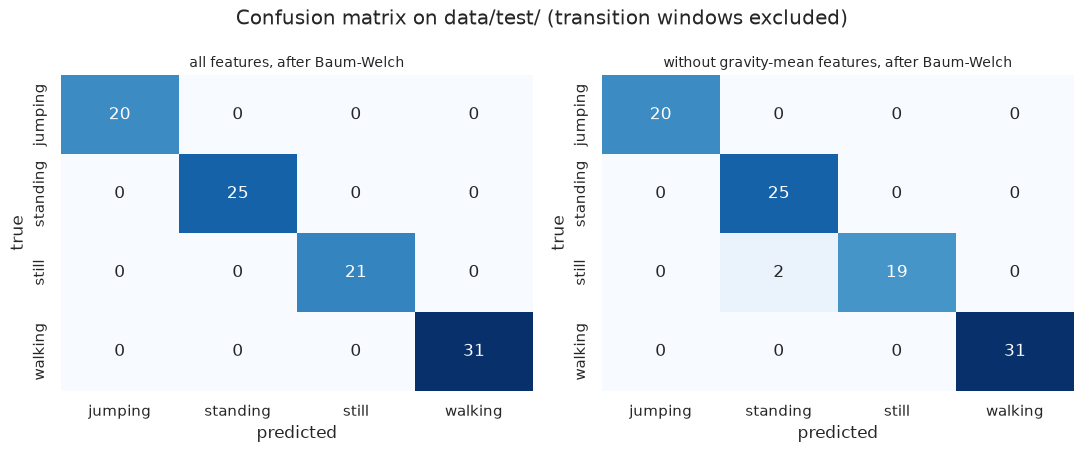

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
for ax, (name, (w, _, _)) in zip(axes, main.items()):
    s = w[w.y >= 0]
    C = confusion_matrix(s.y.values, s.pred_bw.values, 4)
    sns.heatmap(C, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=ACTIVITIES, yticklabels=ACTIVITIES)
    ax.set_title(f"{name}, after Baum-Welch", fontsize=10)
    ax.set_xlabel("predicted"); ax.set_ylabel("true")
fig.suptitle("Confusion matrix on data/test/ (transition windows excluded)")
fig.tight_layout(); savefig(fig, "test_confusion.png"); plt.show()

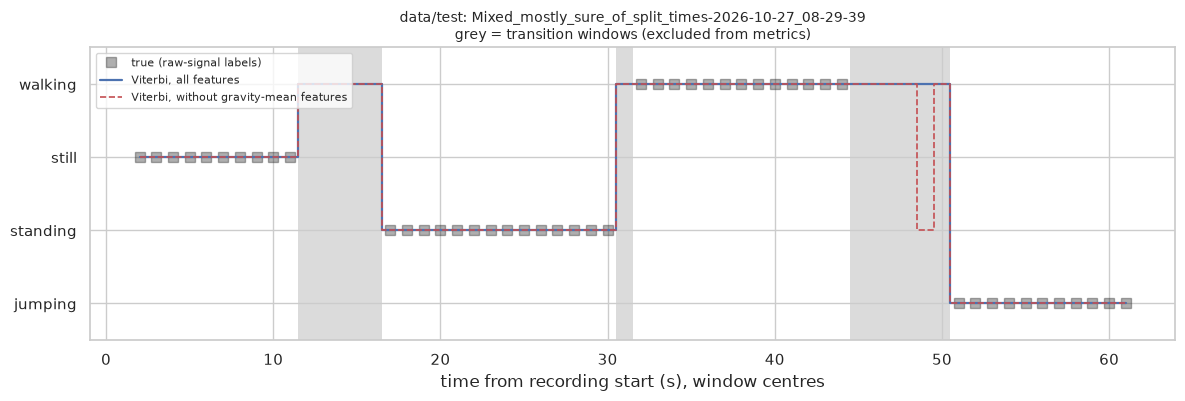

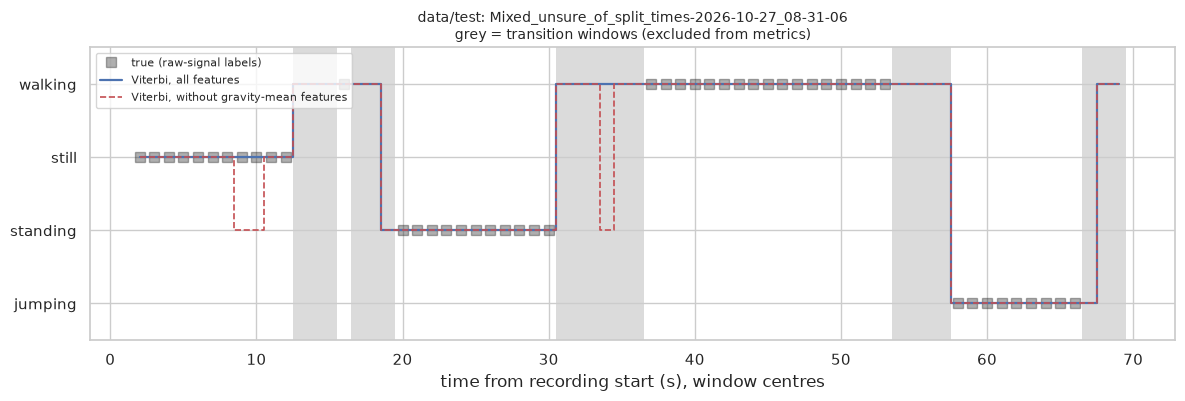

In [7]:
def short(rec):
    return "mostly sure" if "mostly_sure" in rec else ("unsure" if "unsure" in rec else rec)

ymap = {a: i for i, a in enumerate(ACTIVITIES)}
for rec in test_recs:
    fig, ax = plt.subplots(figsize=(14, 3.8))
    w0 = main["all features"][0]
    w0 = w0[w0.recording == rec]
    t = w0.t_s.values + 1.0                                # window centres
    for tt, lab in zip(w0.t_s, w0.label):
        if lab == "transition":
            ax.axvspan(tt + 0.5, tt + 1.5, color="0.8", alpha=0.7, lw=0)
    true = np.where(w0.y >= 0, w0.y, np.nan)
    ax.plot(t, true, "s", ms=7, color="k", alpha=0.35, label="true (raw-signal labels)")
    for (name, (w, _, _)), st in zip(main.items(), [dict(color="C0", lw=1.6), dict(color="C3", lw=1.2, ls="--")]):
        w = w[w.recording == rec]
        ax.step(w.t_s + 1.0, w.pred_bw, where="mid", label=f"Viterbi, {name}", **st)
    ax.set_yticks(range(4)); ax.set_yticklabels(ACTIVITIES); ax.set_ylim(-0.5, 3.5)
    ax.set_xlabel("time from recording start (s), window centres")
    ax.set_title(f"data/test: {rec}\ngrey = transition windows (excluded from metrics)", fontsize=10)
    ax.legend(loc="upper left", fontsize=8)
    savefig(fig, f"test_decoded_{short(rec).replace(' ', '_')}.png"); plt.show()

### Transition windows: how many were excluded and how the model decoded them

In [8]:
w_all, w_nog = main["all features"][0], main["without gravity-mean features"][0]
tr = w_all.label == "transition"
excl = pd.DataFrame({"windows": w_all.groupby("recording").size(),
                     "transition (excluded)": w_all[tr].groupby("recording").size()}).fillna(0).astype(int)
excl.index = excl.index.map(short)
display(excl)
dec = pd.DataFrame({
    "all features": w_all[tr].pred_bw.map(dict(enumerate(ACTIVITIES))).value_counts(),
    "without gravity-mean": w_nog[tr].pred_bw.map(dict(enumerate(ACTIVITIES))).value_counts(),
}).reindex(ACTIVITIES).fillna(0).astype(int)
dec.index.name = "decoded as"
dec

,windows,transition (excluded)
recording,,
mostly sure,60,12
unsure,68,19


,all features,without gravity-mean
decoded as,,
jumping,1,1
standing,1,3
still,0,0
walking,29,27


## 6. Model visualisations (main all-features model)

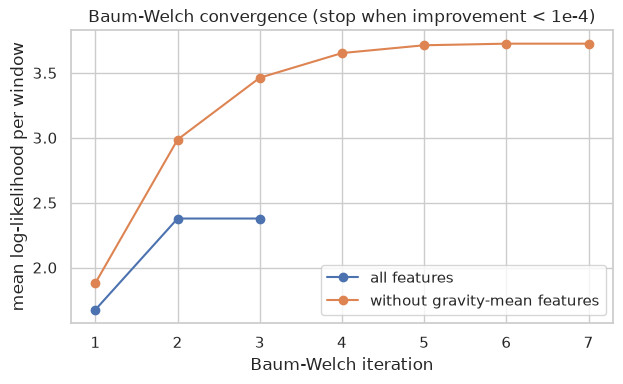

In [9]:
fig, ax = plt.subplots(figsize=(7, 3.8))
for (name, (_, _, f)), c in zip(main.items(), ["C0", "C1"]):
    h = f["bw"].history_
    ax.plot(range(1, len(h) + 1), h, "o-", color=c, label=name)
ax.set_xlabel("Baum-Welch iteration")
ax.set_ylabel("mean log-likelihood per window")
ax.set_title("Baum-Welch convergence (stop when improvement < 1e-4)")
ax.legend()
savefig(fig, "hmm_convergence.png"); plt.show()

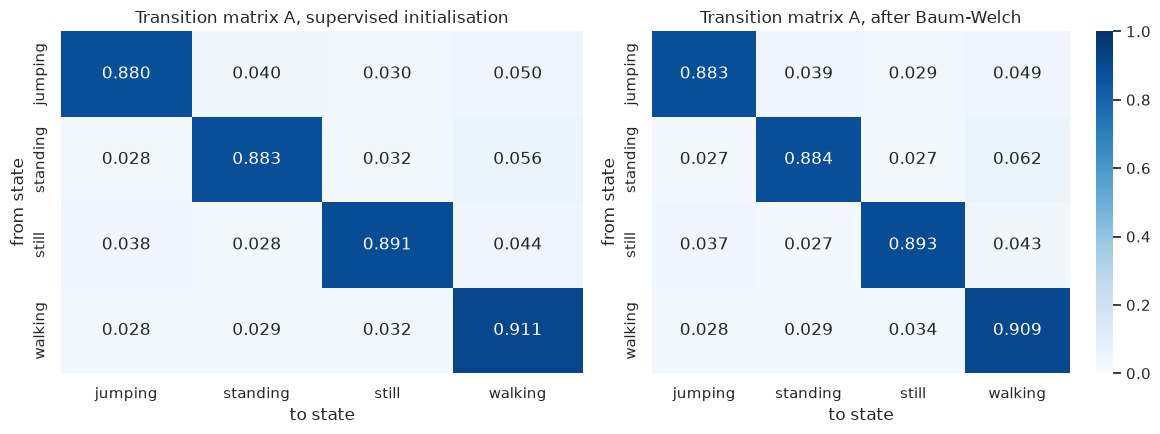

Initial distribution pi (after BW): {'jumping': np.float64(0.1), 'standing': np.float64(0.2), 'still': np.float64(0.4), 'walking': np.float64(0.3)}


In [10]:
F = main["all features"][2]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, (m, title, order) in zip(axes, [(F["init"], "supervised initialisation", np.arange(4)),
                                        (F["bw"], "after Baum-Welch", np.argsort(F["mapping"]))]):
    A = m.transmat_[np.ix_(order, order)]
    sns.heatmap(A, annot=True, fmt=".3f", cmap="Blues", vmin=0, vmax=1, ax=ax,
                xticklabels=ACTIVITIES, yticklabels=ACTIVITIES, cbar=ax is axes[1])
    ax.set_xlabel("to state"); ax.set_ylabel("from state"); ax.set_title(f"Transition matrix A, {title}")
fig.tight_layout(); savefig(fig, "hmm_transition_matrix.png"); plt.show()
print("Initial distribution pi (after BW):",
      dict(zip(ACTIVITIES, F["bw"].startprob_[np.argsort(F["mapping"])].round(3))))

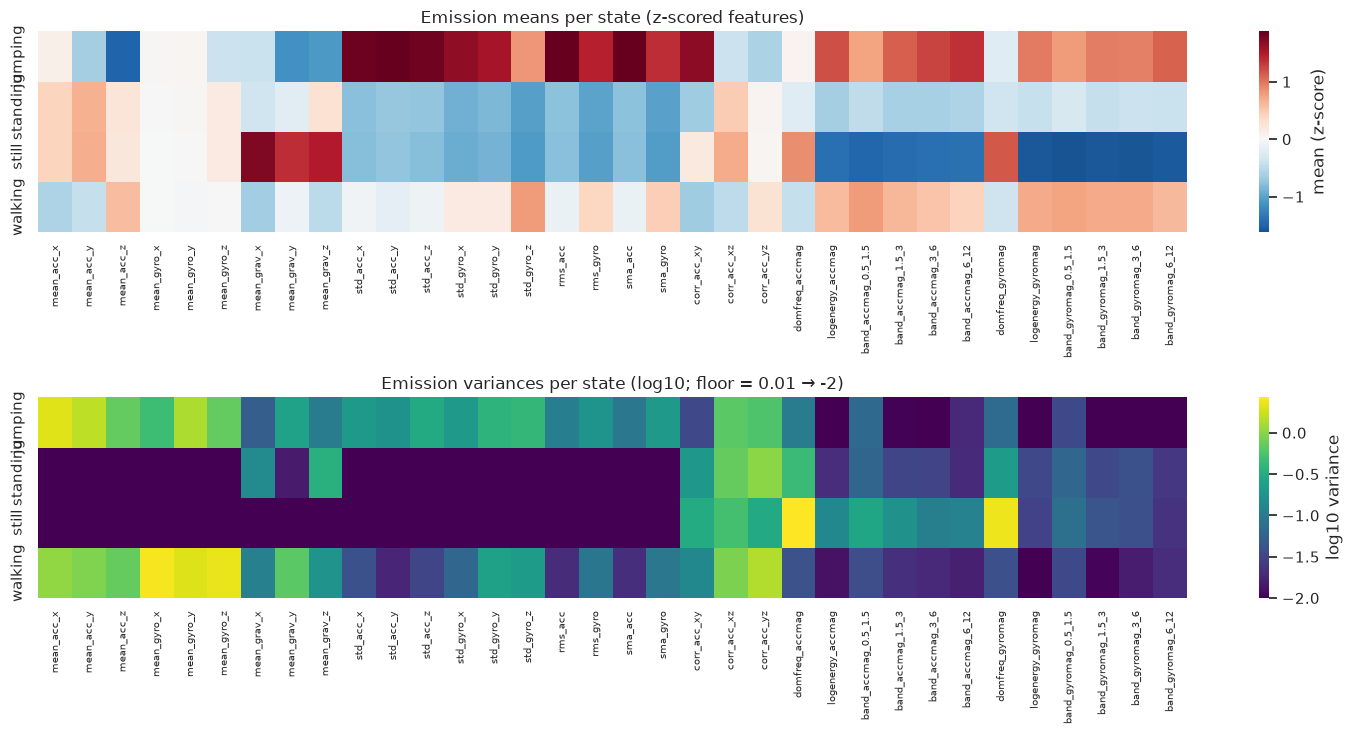

In [11]:
order = np.argsort(F["mapping"])
mu = pd.DataFrame(F["bw"].means_[order], index=ACTIVITIES, columns=F["cols"])
var = pd.DataFrame(F["bw"].vars_[order], index=ACTIVITIES, columns=F["cols"])
fig, axes = plt.subplots(2, 1, figsize=(15, 7.5))
sns.heatmap(mu, cmap="RdBu_r", center=0, ax=axes[0], cbar_kws={"label": "mean (z-score)"})
axes[0].set_title("Emission means per state (z-scored features)")
sns.heatmap(np.log10(var), cmap="viridis", ax=axes[1], cbar_kws={"label": "log10 variance"})
axes[1].set_title("Emission variances per state (log10; floor = 0.01 → -2)")
for ax in axes:
    ax.set_xticklabels(ax.get_xticklabels(), rotation=90, fontsize=7)
fig.tight_layout(); savefig(fig, "hmm_emissions.png"); plt.show()

## 7. Ablation: gravity-mean features

The mean gravity vector differs between activities partly because the phone was **held
differently**: in the first session standing ≈ (−6.5, −3.5, +6.5), jumping ≈ (−7, −5.5, −1.5) and
still flat (0, 0, 9.8); in the second session one grip ≈ (−8, −3, +1) was used for walking, jumping
and standing, and the test recordings add a third standing grip. A model that leans on
`mean_grav_x/y/z` may learn the grip instead of the activity, so every result is reported with and
without these three features (tables and confusion matrices above).

## 8. Supplementary results

### 8a. Temporary hold-out on the training recordings

Whole recordings held out per activity (never chunks of one recording on both sides); the held-out
files are concatenated into one test sequence. Repeated with 10 random seeds.

In [12]:
hold = {name: run(*temporary_holdout(pool)[:2], drop_gravity_mean=drop, name=name) for name, drop in VARIANTS.items()}
hold_rows = [{"features": n, "stage": s, "accuracy": acc, "windows": int(t.windows.sum())}
             for n, r in hold.items() for s, (t, acc) in r.tables.items()]
display(pd.DataFrame(hold_rows).round(3))
rob = []
for seed in range(10):
    tr_, te_, _ = temporary_holdout(pool, seed=seed)
    for name, drop in VARIANTS.items():
        r = run(tr_, te_, drop_gravity_mean=drop)
        rob += [{"seed": seed, "features": name, "stage": s, "accuracy": acc} for s, (_, acc) in r.tables.items()]
rob_summary = pd.DataFrame(rob).groupby(["features", "stage"]).accuracy.agg(["mean", "std", "min", "max"]).round(3)
rob_summary

,features,stage,accuracy,windows
0,all features,before Baum-Welch,0.988,163
1,all features,after Baum-Welch,1.000,163
2,without gravity-mean features,before Baum-Welch,0.982,163
3,without gravity-mean features,after Baum-Welch,0.982,163


mean    std    min  max
features                      stage                                      
all features                  after Baum-Welch   0.999  0.002  0.994  1.0
                              before Baum-Welch  0.999  0.002  0.994  1.0
without gravity-mean features after Baum-Welch   0.993  0.008  0.982  1.0
                              before Baum-Welch  0.998  0.005  0.983  1.0

### 8b. Standing grip check (training sessions)

For each session we hold out **all standing recordings of that session** and train on everything else
(including the other session's standing). If the model relied on orientation, these windows would be
misclassified.

In [13]:
std = pool[pool.activity == "standing"]
std_sess = std.recording.str.extract(r"(\d{4}-\d{2}-\d{2})", expand=False)
grip_rows = []
for sess in sorted(std_sess.unique()):
    te_recs = sorted(std.recording[std_sess == sess].unique())
    tr_recs = sorted(set(pool.recording) - set(te_recs))
    for name, drop in VARIANTS.items():
        w, _, _ = evaluate_recordings(pool, tr_recs, te_recs, drop_gravity_mean=drop)
        for stage, col in [("before Baum-Welch", "pred_init"), ("after Baum-Welch", "pred_bw")]:
            wrong = w[w[col] != w.y][col].map(dict(enumerate(ACTIVITIES))).value_counts()
            grip_rows.append({"held-out standing": f"{sess} ({len(te_recs)} rec.)", "features": name,
                              "stage": stage, "windows": len(w), "correct": int((w[col] == w.y).sum()),
                              "sensitivity": round(float((w[col] == w.y).mean()), 3),
                              "errors predicted as": ", ".join(f"{k} {v}" for k, v in wrong.items()) or "–"})
grip = pd.DataFrame(grip_rows)
grip

,held-out standing,features,stage,windows,correct,sensitivity,errors predicted as
0,2026-10-26 (10 rec.),all features,before Baum-Welch,70,70,1.000,–
1,2026-10-26 (10 rec.),all features,after Baum-Welch,70,70,1.000,–
2,2026-10-26 (10 rec.),without gravity-mean features,before Baum-Welch,70,69,0.986,still 1
3,2026-10-26 (10 rec.),without gravity-mean features,after Baum-Welch,70,69,0.986,still 1
4,2026-10-27 (1 rec.),all features,before Baum-Welch,39,38,0.974,walking 1
5,2026-10-27 (1 rec.),all features,after Baum-Welch,39,38,0.974,walking 1
6,2026-10-27 (1 rec.),without gravity-mean features,before Baum-Welch,39,38,0.974,walking 1
7,2026-10-27 (1 rec.),without gravity-mean features,after Baum-Welch,39,38,0.974,walking 1


### 8c. Cross-session test (trained on 2026-10-26 only, tested on the 2026-10-27 single-activity recordings)

In [14]:
cs = (REPORTS / "cross_session_test.md")
cs_summary = re.search(r"<!-- summary -->\n(.*?)\n<!-- /summary -->", cs.read_text(), re.S).group(1) if cs.exists() else "Not run (python src/cross_session.py)."
display(Markdown(cs_summary))

Model trained only on the 2026-10-26 session (31 recordings), tested on the 7 recordings of 2026-10-27: **a different session and a different grip** (mean gravity ~ (-8, -3, +1) for every activity; old standing was ~ (-6.5, -3.5, +6.5)). Default 1 s trims, before any trim overrides.
- **all features**: overall accuracy 0.980 (200 windows); sensitivity jumping 1.000, standing 0.905, walking 1.000
- **without gravity-mean features**: overall accuracy 0.980 (200 windows); sensitivity jumping 1.000, standing 0.905, walking 1.000
- All errors are in the new standing file, at t = 1, 45, 46, 47 s (2 s windows; file is ~50 s long): the phone settling at the start and being picked up at the end (motion and tilt jump in those windows), not the standing itself.
- Full details: `reports/cross_session_test.md`.

## 9. Write `reports/metrics_table.md`

In [15]:
L = ["# HMM metrics", "",
     "## Main evaluation: data/test/ (2 continuous recordings)", "",
     "Labels from raw signals only (`src/segment.py`, `data/test/labels.csv`). Windows: 2 s, 50 % overlap "
     "(1 s hop) at 50 Hz; a window is labelled only if >= 75 % of it lies in one segment, otherwise it is "
     "`transition` and excluded from the metrics. Each recording is Viterbi-decoded as one continuous "
     "sequence. Sensitivity = TP/(TP+FN), specificity = TN/(TN+FP), one-vs-rest. Model trained on all "
     f"{len(train_recs)} single-activity recordings.", "",
     "| Features | Stage | Accuracy | Macro sensitivity | Macro specificity |", "|---|---|---:|---:|---:|"]
L += [f"| {r.features} | {r.stage} | {r.accuracy:.3f} | {r['macro sensitivity']:.3f} | {r['macro specificity']:.3f} |"
      for _, r in summary.iterrows()]
L += ["", "### Per-activity tables", ""] + sections
L += ["### Transition windows (excluded from the metrics)", "",
      "| Recording | Windows | Transition (excluded) |", "|---|---:|---:|"]
L += [f"| {i} | {r.windows} | {r['transition (excluded)']} |" for i, r in excl.iterrows()]
L += ["", "How the model decoded the transition windows (after Baum-Welch):", "",
      "| Decoded as | All features | Without gravity-mean |", "|---|---:|---:|"]
L += [f"| {i} | {r['all features']} | {r['without gravity-mean']} |" for i, r in dec.iterrows()]
L += ["", "Figures: `figures/test_confusion.png`, `figures/test_decoded_*.png`, "
      "`figures/hmm_transition_matrix.png`, `figures/hmm_emissions.png`, `figures/hmm_convergence.png`.", "",
      "## Supplementary", "",
      "### Temporary hold-out on the training recordings (whole recordings held out)", "",
      "| Features | Stage | Accuracy | Windows |", "|---|---|---:|---:|"]
L += [f"| {r['features']} | {r['stage']} | {r['accuracy']:.3f} | {r['windows']} |" for r in hold_rows]
L += ["", "10 random hold-outs (accuracy):", "",
      "| Features | Stage | Mean | Std | Min | Max |", "|---|---|---:|---:|---:|---:|"]
L += [f"| {f} | {s} | {r['mean']:.3f} | {r['std']:.3f} | {r['min']:.3f} | {r['max']:.3f} |"
      for (f, s), r in rob_summary.iterrows()]
L += ["", "### Standing grip check (all standing of one session held out)", "",
      "| Held-out standing | Features | Stage | Windows | Correct | Sensitivity | Errors predicted as |",
      "|---|---|---|---:|---:|---:|---|"]
L += [f"| {r['held-out standing']} | {r.features} | {r.stage} | {r.windows} | {r.correct} | "
      f"{r.sensitivity:.3f} | {r['errors predicted as']} |" for _, r in grip.iterrows()]
L += ["", "### Cross-session test", "", cs_summary, ""]
(REPORTS / "metrics_table.md").write_text("\n".join(L) + "\n")
print("wrote", REPORTS / "metrics_table.md")

wrote /home/shem-ayioka/Desktop/reports/metrics_table.md


## 10. Discussion

See the tables above and `reports/metrics_table.md` / `reports/report_facts.md` for the numbers.

* **Separability.** Jumping, walking and the two static classes differ by orders of magnitude in
  RMS/SMA and spectral energy, so the emission model separates them almost perfectly, also on the
  continuous test recordings that the model never saw.
* **Hardest pair: still vs standing.** Both are static. The new still recording is about 4× noisier
  than the first-session still (different surface or vibration), which narrows the margin to standing;
  without the gravity features this is where errors appear.
* **Grip.** Standing now appears in three grips. The grip check and the test recordings show whether
  the model recognises standing from motion level rather than from one phone orientation.
* **Transitions.** Phone handling between activities lasts 3–6 s. The HMM has no "transition" state,
  so it must assign these windows to one of the four activities (see the transition table); a fifth
  state, or a reject option based on low emission likelihood, would be the natural extension.
* **Baum–Welch** starts from the supervised solution and converges in a few iterations. It is
  unsupervised, so it optimises likelihood, not accuracy, and can shift cluster boundaries in either
  direction.
* **Transition matrix** is strongly diagonal; the off-diagonal mass reflects our synthetic
  concatenation, not real behaviour. Viterbi uses it to smooth out isolated misclassified windows.
* **Limitations.** Two test recordings from one person, one phone and one session; labels from a
  raw-signal rule with ~±1 s boundary uncertainty; orientation confound (section 7).